Tehtävä 10
Tarkastellaan signaalia

s(t)=sin(2π⋅0,2t)+0,5sin(2π⋅1,2t).
a) Muodosta signaali Pythonilla 100 Hz:n näytteenottotaajuudella aikavälillä 0≤t<30 s.

b) Poimi siitä havainnot sekunnin välein ja piirrä ne alkuperäisen signaalin päälle.

c) Mitkä alkuperäisen signaalin taajuudet voidaan erottaa 1 Hz:n näytteistyksellä?

d) Suodata korkeataajuinen komponentti pois ennen näytteenottotaajuuden pienentämistä. Valitse alipäästösuodatin, joka säilyttää 0,2 Hz:n komponentin ja vaimentaa 1,2 Hz:n komponenttia. Perustele suodattimen valinta ja tarkista sen vaikutus komponenttien amplitudeihin.

e) Vertaa suodatettua ja suodattamatonta tulosta. Selitä havaintosi.

[ 0.00000000e+00  1.42658477e+00  8.81677878e-01 -8.81677878e-01
 -1.42658477e+00 -9.79717439e-16  1.42658477e+00  8.81677878e-01
 -8.81677878e-01 -1.42658477e+00 -1.95943488e-15  1.42658477e+00
  8.81677878e-01 -8.81677878e-01 -1.42658477e+00 -2.93915232e-15
  1.42658477e+00  8.81677878e-01 -8.81677878e-01 -1.42658477e+00
 -3.91886976e-15  1.42658477e+00  8.81677878e-01 -8.81677878e-01
 -1.42658477e+00 -1.20040146e-14  1.42658477e+00  8.81677878e-01
 -8.81677878e-01 -1.42658477e+00]


<function matplotlib.pyplot.show(close=None, block=None)>

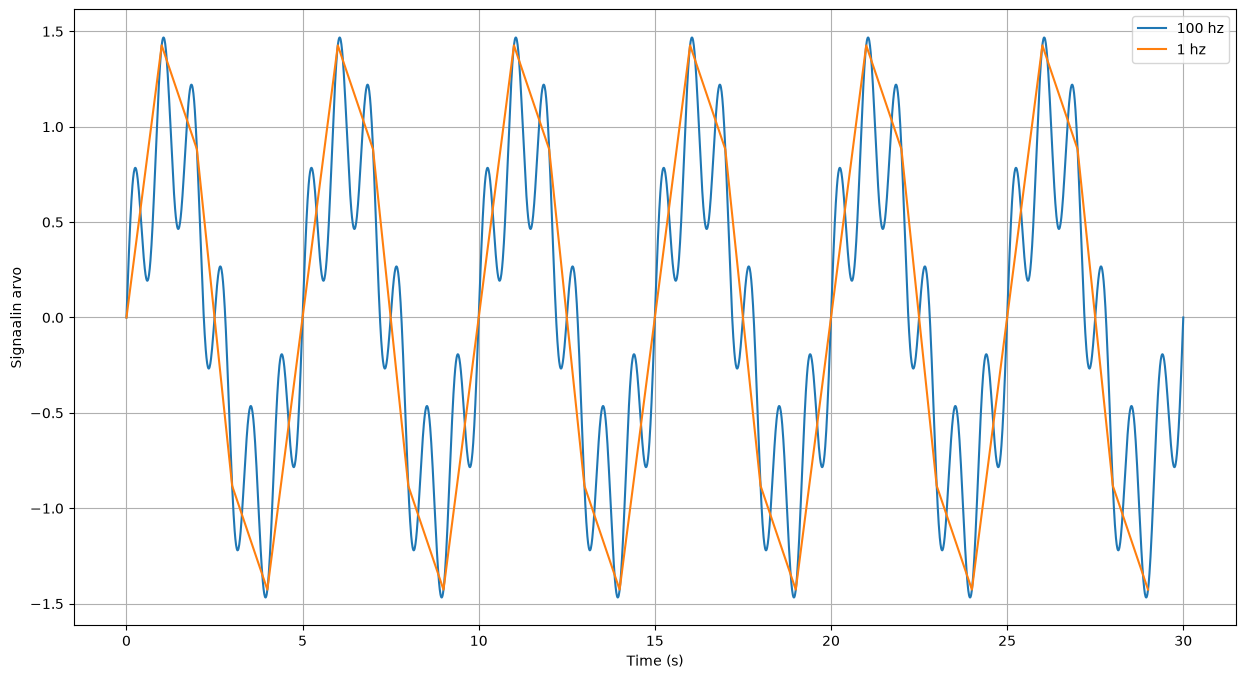

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#a) b)
plt.figure(figsize=(15,8))
t = np.linspace(0, 30, 3000)
t_sek = np.arange(0, 30, 1)

s = np.sin(2*np.pi*0.2*t) + 0.5*np.sin(2*np.pi*1.2*t)
s_sek = np.sin(2*np.pi*0.2*t_sek) + 0.5*np.sin(2*np.pi*1.2*t_sek)
plt.plot(t, s, label="100 hz")
plt.plot(t_sek, s_sek, label="1 hz")

#c) 
#0, 1.4, 0.8, -1.4 ja -0.8



plt.xlabel('Time (s)')
plt.ylabel("Signaalin arvo")
plt.legend()
plt.grid()
plt.show


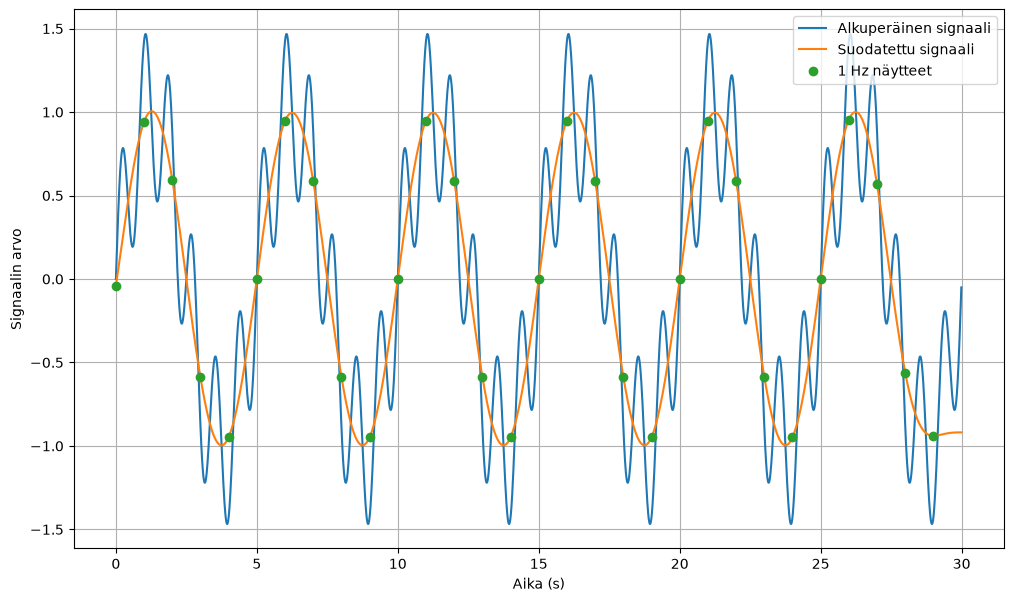

In [ ]:
from scipy.signal import butter, sosfiltfilt

fs = 100
t = np.linspace(0, 30, fs * 30, endpoint=False)

s = np.sin(2*np.pi*0.2*t) + 0.5*np.sin(2*np.pi*1.2*t)

# Alipäästösuodatin
fc = 0.4  # Rajataajuus 0,4 Hz
sos = butter(4, fc, btype="lowpass", fs=fs, output="sos")

# Suodatetaan signaali
s_filtered = sosfiltfilt(sos, s)

# Pienennetään näytteenottotaajuus 1 Hz:iin
t_1hz = t[::100]
s_1hz = s_filtered[::100]

# Piirretään kuvaajat
plt.figure(figsize=(12, 7))

plt.plot(t, s, label="Alkuperäinen signaali")
plt.plot(t, s_filtered, label="Suodatettu signaali")
plt.plot(t_1hz, s_1hz, "o", label="1 Hz näytteet")

plt.xlabel("Aika (s)")
plt.ylabel("Signaalin arvo")
plt.legend()
plt.grid()
plt.show()

#Kuvaaja havainnollistaa hyvin, miksi signaali kannattaa suodattaa ennen näytteenottotaajuuden pienentämistä.

#Ilman suodatusta 1,2 Hz:n komponentti laskostuisi 0,2 Hz:n taajuudeksi. Suodattamisen jälkeen sen vaikutus on hyvin pieni.
